In [1]:
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score

In [2]:
# Load the dataset

df = pd.read_csv("employee_turnover.csv")
df

,Job_Satisfaction,Performance_Rating,Years_At_Company,Work_Life_Balance,Distance_From_Home,Monthly_Income,Education_Level,Age,Num_Companies_Worked,Employee_Role,Annual_Bonus,Training_Hours,Department,Annual_Bonus_Squared,Annual_Bonus_Training_Hours_Interaction,Employee_Turnover
0,0.562326,0.141129,0.123989,0.347583,0.330353,0.328853,0.600933,0.315990,0.768736,0.090671,0.324786,0.669193,0.602932,0.105486,0.217344,0
1,0.017041,0.559047,0.511203,0.793908,0.423550,0.553450,0.742009,0.897146,0.380035,0.601633,0.694611,0.043271,0.800761,0.482484,0.030056,0
2,0.774699,0.604371,0.798174,0.260500,0.804034,0.131800,0.775178,0.830947,0.218726,0.972936,0.153476,0.701336,0.705275,0.023555,0.107638,1
3,0.628174,0.385249,0.230104,0.516809,0.272248,0.589249,0.482409,0.090507,0.402746,0.132842,0.305973,0.549688,0.600531,0.093620,0.168190,0
4,0.799183,0.199967,0.839029,0.247927,0.341934,0.076818,0.055356,0.680860,0.923341,0.493017,0.844094,0.793751,0.664679,0.712494,0.670000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1345,0.914733,0.965914,0.147215,0.686677,0.251346,0.572003,0.089679,0.127247,0.125553,0.346950,0.450783,0.754675,0.905320,0.203205,0.340194,1
1346,0.396906,0.182952,0.877941,0.824077,0.774960,0.057290,0.556719,0.235014,0.119685,0.781613,0.211581,0.500812,0.526096,0.044767,0.105962,1
1347,0.099171,0.363498,0.849120,0.462270,0.763922,0.585370,0.975760,0.557090,0.782690,0.384706,0.449095,0.270280,0.253656,0.201686,0.121381,1
1348,0.048193,0.453892,0.640611,0.335230,0.952724,0.638797,0.993664,0.801292,0.510281,0.164325,0.649934,0.151225,0.405705,0.422414,0.098286,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1350 entries, 0 to 1349
Data columns (total 16 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Job_Satisfaction                         1350 non-null   float64
 1   Performance_Rating                       1350 non-null   float64
 2   Years_At_Company                         1350 non-null   float64
 3   Work_Life_Balance                        1350 non-null   float64
 4   Distance_From_Home                       1350 non-null   float64
 5   Monthly_Income                           1350 non-null   float64
 6   Education_Level                          1350 non-null   float64
 7   Age                                      1350 non-null   float64
 8   Num_Companies_Worked                     1350 non-null   float64
 9   Employee_Role                            1350 non-null   float64
 10  Annual_Bonus                             1350 non-null   fl

In [4]:
df.describe()

,Job_Satisfaction,Performance_Rating,Years_At_Company,Work_Life_Balance,Distance_From_Home,Monthly_Income,Education_Level,Age,Num_Companies_Worked,Employee_Role,Annual_Bonus,Training_Hours,Department,Annual_Bonus_Squared,Annual_Bonus_Training_Hours_Interaction,Employee_Turnover
count,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1350.000000,1.350000e+03,1350.000000,1350.000000
mean,0.506386,0.487061,0.484761,0.499442,0.494884,0.509909,0.504329,0.500164,0.516149,0.506091,0.493360,0.486843,0.485767,3.291479e-01,0.240653,0.497778
std,0.291505,0.283808,0.282758,0.293013,0.289248,0.290110,0.295693,0.294835,0.295072,0.284901,0.292929,0.288342,0.285077,2.986314e-01,0.222281,0.500180
min,0.001738,0.000546,0.001545,0.000166,0.001319,0.005015,0.000424,0.000231,0.000150,0.000903,0.000491,0.001293,0.001595,2.410000e-07,0.000247,0.000000
25%,0.263051,0.238538,0.249651,0.246399,0.244162,0.263235,0.249894,0.239224,0.247978,0.269517,0.247274,0.233357,0.244944,6.114448e-02,0.058694,0.000000
50%,0.525340,0.468457,0.485414,0.495572,0.501617,0.532388,0.509448,0.499964,0.531408,0.504640,0.498490,0.475214,0.468982,2.484923e-01,0.165438,0.000000
75%,0.750987,0.724088,0.721622,0.753108,0.743938,0.761090,0.755113,0.767168,0.775888,0.761640,0.740231,0.747609,0.725870,5.479425e-01,0.367042,1.000000
max,0.998692,0.999957,0.999722,0.999931,0.997813,0.999143,0.999794,0.998365,0.999962,0.999964,0.998211,0.998330,0.999386,9.964245e-01,0.930338,1.000000


In [5]:
df['Employee_Turnover'].value_counts()

Employee_Turnover
0    678
1    672
Name: count, dtype: int64

In [6]:
df['Employee_Turnover'].value_counts(normalize=True) * 100

Employee_Turnover
0    50.222222
1    49.777778
Name: proportion, dtype: float64

In [7]:
df.duplicated().sum()

np.int64(450)

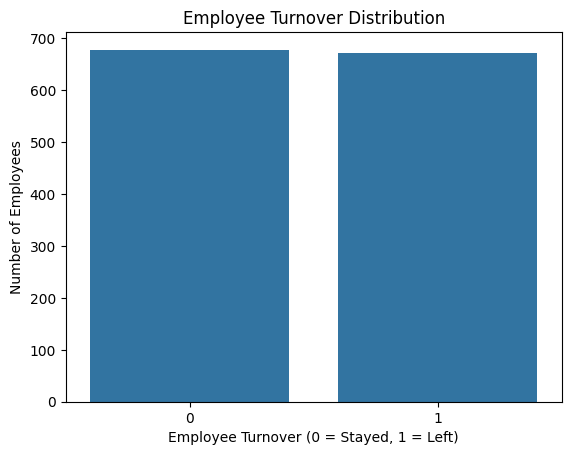

In [8]:
import matplotlib.pyplot as plt

# Purpose: Visualize employee turnover distribution

sns.countplot(data=df, x='Employee_Turnover')

plt.title('Employee Turnover Distribution')
plt.xlabel('Employee Turnover (0 = Stayed, 1 = Left)')
plt.ylabel('Number of Employees')
plt.show()

In [9]:
# Remove duplicate records

df = df.drop_duplicates()

print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (900, 16)
Duplicate Rows: 0


In [10]:
df.isnull().sum()

Job_Satisfaction                           0
Performance_Rating                         0
Years_At_Company                           0
Work_Life_Balance                          0
Distance_From_Home                         0
Monthly_Income                             0
Education_Level                            0
Age                                        0
Num_Companies_Worked                       0
Employee_Role                              0
Annual_Bonus                               0
Training_Hours                             0
Department                                 0
Annual_Bonus_Squared                       0
Annual_Bonus_Training_Hours_Interaction    0
Employee_Turnover                          0
dtype: int64

In [11]:
print(df['Employee_Turnover'].value_counts())

Employee_Turnover
0    458
1    442
Name: count, dtype: int64


In [12]:
# Check Feature distributions

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Job_Satisfaction,900.0,0.503075,0.290274,1.737827e-03,0.260270,0.515819,0.748402,0.998692
Performance_Rating,900.0,0.484277,0.286212,5.459650e-04,0.229085,0.466680,0.725909,0.999957
Years_At_Company,900.0,0.481606,0.285024,1.545250e-03,0.242785,0.479218,0.719292,0.999722
Work_Life_Balance,900.0,0.498687,0.292415,1.664410e-04,0.245345,0.495572,0.751186,0.999931
Distance_From_Home,900.0,0.494243,0.290618,1.319025e-03,0.239066,0.500337,0.744289,0.997813
Monthly_Income,900.0,0.511904,0.291192,5.015471e-03,0.261346,0.533535,0.763777,0.999143
Education_Level,900.0,0.501421,0.293249,4.235700e-04,0.253448,0.507975,0.744823,0.999794
Age,900.0,0.499978,0.293726,2.305850e-04,0.240940,0.499659,0.764133,0.998365
Num_Companies_Worked,900.0,0.512197,0.296530,1.503810e-04,0.239618,0.525354,0.773421,0.999962
Employee_Role,900.0,0.505051,0.285004,9.032860e-04,0.268713,0.502396,0.760824,0.999964


In [13]:
# Separate Features (X) and Target (y)

X = df.drop('Employee_Turnover', axis=1)

y = df['Employee_Turnover']

In [14]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (900, 15)
Target Shape: (900,)

Feature Columns:
['Job_Satisfaction', 'Performance_Rating', 'Years_At_Company', 'Work_Life_Balance', 'Distance_From_Home', 'Monthly_Income', 'Education_Level', 'Age', 'Num_Companies_Worked', 'Employee_Role', 'Annual_Bonus', 'Training_Hours', 'Department', 'Annual_Bonus_Squared', 'Annual_Bonus_Training_Hours_Interaction']


In [15]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [16]:
# Verify the split

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (720, 15)
X_test: (180, 15)
y_train: (720,)
y_test: (180,)


In [17]:
# Implement StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Only transform testing data
X_test_scaled = scaler.transform(X_test)

In [18]:
# Verify Scaled data

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nMean of scaled features:")
print(X_train_scaled.mean(axis=0))

print("\nStandard deviation:")
print(X_train_scaled.std(axis=0))

Training Data Shape: (720, 15)
Testing Data Shape: (180, 15)

Mean of scaled features:
[ 4.00913870e-17 -1.48029737e-16  0.00000000e+00 -2.02924097e-16
  8.88178420e-17 -1.97372982e-17 -2.96059473e-16  4.68760833e-17
  2.29446092e-16  1.27058857e-16  3.57738530e-17 -4.44089210e-17
 -1.62215920e-16 -2.96059473e-17 -1.15956627e-16]

Standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [20]:
# Train the Baseline Model

lr_baseline = LogisticRegression(
    penalty=None,
    max_iter=10000,
    random_state=42
)

lr_baseline.fit(X_train_scaled, y_train)

C:\Users\ASR\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` p

In [21]:
# Make Prediction 

y_pred_baseline = lr_baseline.predict(X_test_scaled)

In [22]:
# Probability predictions:

y_probability = lr_baseline.predict_proba(X_test_scaled)

print(y_probability[:5])

[[9.36739780e-01 6.32602197e-02]
 [9.99960554e-01 3.94462009e-05]
 [9.92482302e-01 7.51769818e-03]
 [7.23739970e-04 9.99276260e-01]
 [2.74333725e-01 7.25666275e-01]]


In [23]:
# Evaluate Model Performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_baseline))

print("Precision:", precision_score(y_test, y_pred_baseline))

print("Recall:", recall_score(y_test, y_pred_baseline))

print("F1 Score:", f1_score(y_test, y_pred_baseline))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))

Accuracy: 0.8833333333333333
Precision: 0.9036144578313253
Recall: 0.8522727272727273
F1 Score: 0.8771929824561403

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.91      0.89        92
           1       0.90      0.85      0.88        88

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



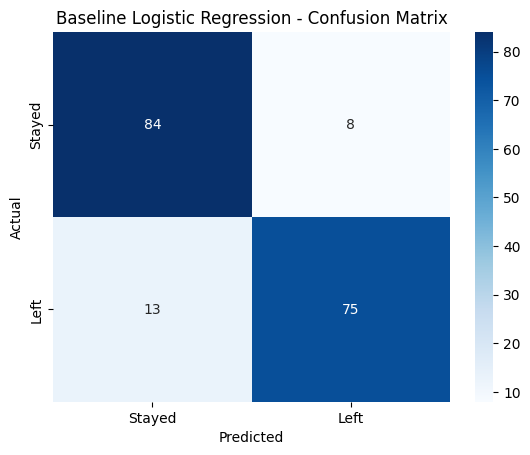

In [24]:
# Understand the Confusion Matrix

cm = confusion_matrix(y_test, y_pred_baseline)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Baseline Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [25]:
# Implement L1 Regularization

lr_l1 = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=1.0,
    max_iter=1000,
    random_state=42
)

lr_l1.fit(X_train_scaled, y_train)

C:\Users\ASR\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ASR\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` p

In [26]:
# Make Prediction 

y_pred_l1 = lr_l1.predict(X_test_scaled)

In [27]:
# Evaluate L1 model

print("L1 Accuracy:", accuracy_score(y_test, y_pred_l1))

print("L1 Precision:", precision_score(y_test, y_pred_l1))

print("L1 Recall:", recall_score(y_test, y_pred_l1))

print("L1 F1 Score:", f1_score(y_test, y_pred_l1))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_l1))

L1 Accuracy: 0.8722222222222222
L1 Precision: 0.891566265060241
L1 Recall: 0.8409090909090909
L1 F1 Score: 0.8654970760233918

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88        92
           1       0.89      0.84      0.87        88

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



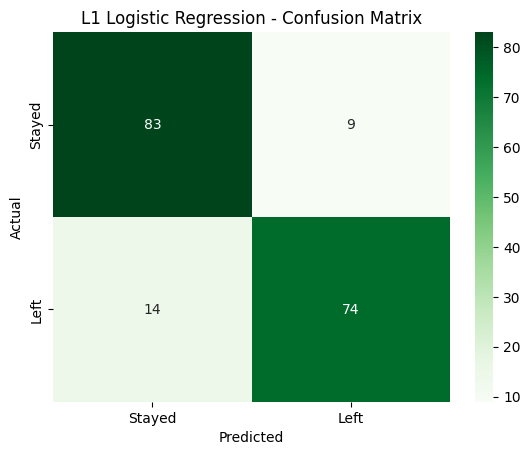

In [28]:
# Visualize Confusion Matrix

cm_l1 = confusion_matrix(y_test, y_pred_l1)

sns.heatmap(
    cm_l1,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('L1 Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [29]:
# Check feature coefficient

l1_coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_l1.coef_[0]
})

print(l1_coefficients.sort_values(
    by='Coefficient',
    key=abs,
    ascending=False
))

                                    Feature  Coefficient
0                          Job_Satisfaction     1.799030
1                        Performance_Rating     1.775436
3                         Work_Life_Balance     1.745611
4                        Distance_From_Home     1.587155
2                          Years_At_Company     1.444094
6                           Education_Level    -0.304665
13                     Annual_Bonus_Squared     0.172510
12                               Department    -0.169333
9                             Employee_Role     0.132362
14  Annual_Bonus_Training_Hours_Interaction    -0.077441
8                      Num_Companies_Worked    -0.044021
5                            Monthly_Income    -0.025151
7                                       Age    -0.023779
10                             Annual_Bonus    -0.022218
11                           Training_Hours     0.000000


In [30]:
print("Total Features:", len(lr_l1.coef_[0]))

print("Zero Coefficients:",
      (lr_l1.coef_[0] == 0).sum())

Total Features: 15
Zero Coefficients: 1


In [31]:
# Train L2 Logistic Regression Model

lr_l2 = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    C=1.0,
    max_iter=1000,
    random_state=42
)

lr_l2.fit(X_train_scaled, y_train)

C:\Users\ASR\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` p

In [32]:
# Make Prediction 

y_pred_l2 = lr_l2.predict(X_test_scaled)

In [33]:
# Evaluate L2 Model

print("L2 Accuracy:", accuracy_score(y_test, y_pred_l2))

print("L2 Precision:", precision_score(y_test, y_pred_l2))

print("L2 Recall:", recall_score(y_test, y_pred_l2))

print("L2 F1 Score:", f1_score(y_test, y_pred_l2))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_l2))

L2 Accuracy: 0.8777777777777778
L2 Precision: 0.8928571428571429
L2 Recall: 0.8522727272727273
L2 F1 Score: 0.872093023255814

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88        92
           1       0.89      0.85      0.87        88

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



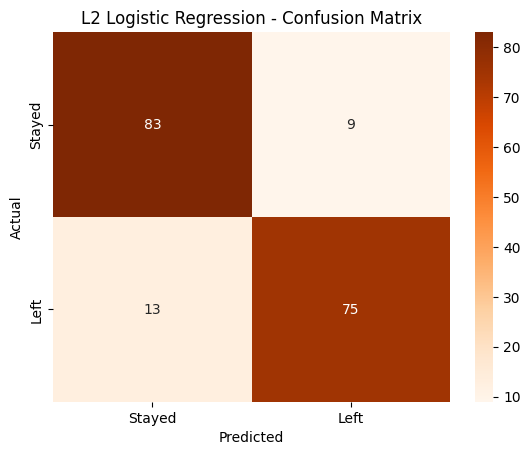

In [34]:
# Confusion Matrix

cm_l2 = confusion_matrix(y_test, y_pred_l2)

sns.heatmap(
    cm_l2,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('L2 Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [35]:
# Check L2 coefficient

l2_coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_l2.coef_[0]
})

print(
    l2_coefficients.sort_values(
        by='Coefficient',
        key=abs,
        ascending=False
    )
)

                                    Feature  Coefficient
0                          Job_Satisfaction     1.746035
1                        Performance_Rating     1.728345
3                         Work_Life_Balance     1.695179
4                        Distance_From_Home     1.538646
2                          Years_At_Company     1.406798
13                     Annual_Bonus_Squared     0.460727
6                           Education_Level    -0.310126
10                             Annual_Bonus    -0.290375
12                               Department    -0.175526
9                             Employee_Role     0.146923
14  Annual_Bonus_Training_Hours_Interaction    -0.112134
8                      Num_Companies_Worked    -0.056327
5                            Monthly_Income    -0.037445
7                                       Age    -0.032748
11                           Training_Hours     0.017797


In [36]:
# Create a Model Comparison Dataframe

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_results = {
    'Model': ['Baseline', 'L1 Regularization', 'L2 Regularization'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_l1),
        accuracy_score(y_test, y_pred_l2)
    ],

    'Precision': [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_l1),
        precision_score(y_test, y_pred_l2)
    ],

    'Recall': [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred_l1),
        recall_score(y_test, y_pred_l2)
    ],

    'F1_Score': [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_l1),
        f1_score(y_test, y_pred_l2)
    ]
}

comparison_df = pd.DataFrame(model_results)

print(comparison_df.round(4))

               Model  Accuracy  Precision  Recall  F1_Score
0           Baseline    0.8833     0.9036  0.8523    0.8772
1  L1 Regularization    0.8722     0.8916  0.8409    0.8655
2  L2 Regularization    0.8778     0.8929  0.8523    0.8721


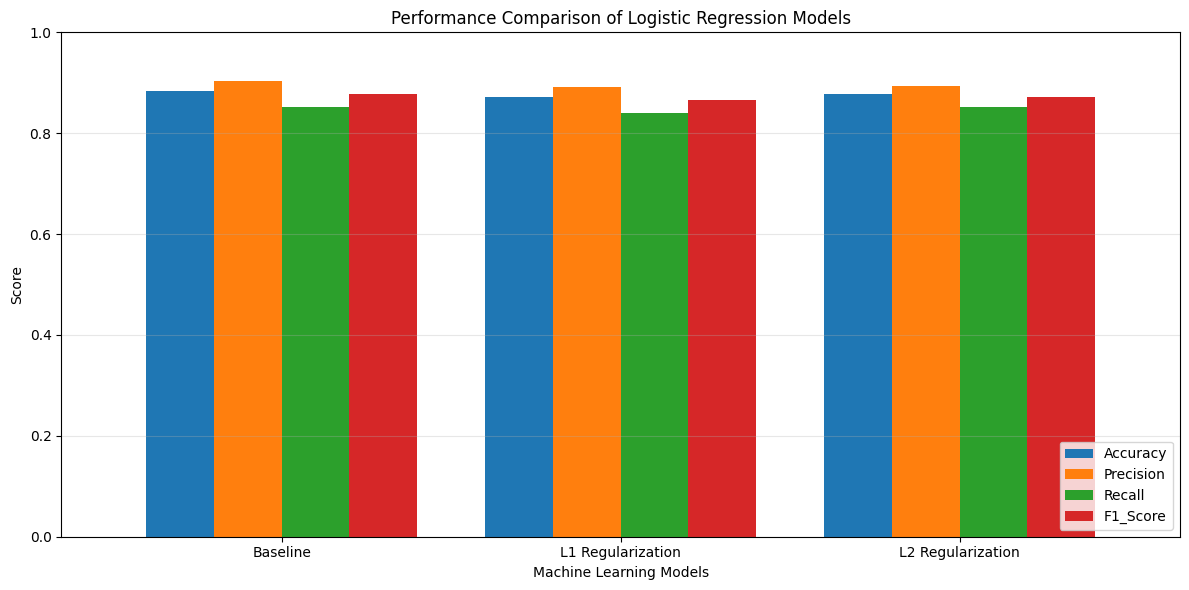

In [37]:
# Visualize Model Performance

metrics = ['Accuracy', 'Precision', 'Recall', 'F1_Score']

comparison_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Performance Comparison of Logistic Regression Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# Identify the Best Model

best_model_name = comparison_df.loc[
    comparison_df['F1_Score'].idxmax(),
    'Model'
]

print("Best Model:", best_model_name)

Best Model: Baseline
